# CS664 Assignment1 - Part1 - Wei Zhao

In [1]:
from hw1_helpers_poole import roll_dice, Environment, Agent, Simulate
import random
import matplotlib.pyplot as plt

In [2]:
class Dice_agent(Agent):

    def __init__(self):
        self.agent_history = []
    
    def select_action(self, percept):
        d1, d2 = percept
        if d1 == d2:
            shares = random.randint(25, 50)
            action = 'Buy'
            self.agent_history.append(shares)
        elif d1 + d2 == 7:
            shares = random.randint(50, 75)
            action = 'Buy'
            self.agent_history.append(shares)
        else:
            shares = random.randint(1, 25)
            action = 'Sell'
            self.agent_history.append(-shares)
        return action, shares
        


In [3]:
class Dice_Env(Environment):
    def __init__(self):
        self.shares = 100
        self.history = [self.shares]
               
    def initial_percept(self):
        return roll_dice()

    def do(self, action):
        todo, qty = action
        if todo == 'Buy':
            self.shares += qty
        elif todo == 'Sell':
            self.shares -= qty
        self.history.append(self.shares)
        return roll_dice()


In [4]:
class Plot_history(object):
    """Set up the plot for history of price and number in stock"""
    def __init__(self, ag, env):
        self.ag = ag
        self.env = env
        plt.ion()
        plt.xlabel("Time")
        plt.ylabel("Value")
        plt.title("Agent & Environment History - Wei Zhao")
        

    def plot_env_hist(self):
        """plot history of current shares"""
        num = len(self.env.history)
        plt.plot(range(num), self.env.history, label="Current Shares")
        plt.xticks(range(0, num+1))
        plt.legend()
        plt.draw()

    def plot_agent_hist(self):
        """plot history of buying/selling"""
        num = len(self.ag.agent_history)
        plt.axhline(0, color='black', linestyle='-', linewidth=1.2)
        plt.bar(range(1,num+1), self.ag.agent_history, label="Bought/Sold")
        plt.xticks(range(0, num+1))
        plt.legend()
        plt.draw()

Starting shares: 100
Ending shares: 152
Agent history: [-21, -17, -10, 33, -16, 28, -3, 44, -7, 50, -23, -5, -9, -11, -25, -21, 32, 68, -10, -25]
Environment history: [100, 79, 62, 52, 85, 69, 97, 94, 138, 131, 181, 158, 153, 144, 133, 108, 87, 119, 187, 177, 152]


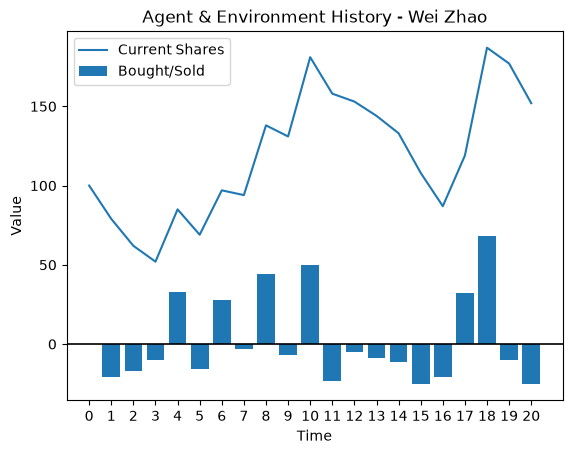

In [5]:
#test code
random.seed(6449)

ag = Dice_agent()
env = Dice_Env()

Simulate.max_display_level = 1
sim = Simulate(ag, env)

sim.go(20)

print(f"Starting shares: {env.history[0]}")
print(f"Ending shares: {env.shares}")
print(f"Agent history: {ag.agent_history}")
print(f"Environment history: {env.history}")

pl = Plot_history(ag,env); pl.plot_env_hist(); pl.plot_agent_hist();
